## Importing libraries

In [40]:
import pandas as pd
import streamlit as st
from itables import show
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
%matplotlib inline

## Importing data

In [33]:
currency_processed = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_processed/currency_processed.csv", sep=";", low_memory=False)
items_processed = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_processed/items_processed.csv", sep=";", low_memory=False)

# Actual Exploratory Data Analysis - market economy analysis

## Dataset overwiev

In [27]:
print(f"number of items: {items_processed['Name'].nunique()}")
print(f"number of leagues: {items_processed['League'].nunique()}")

number of items: 10797
number of leagues: 6


To perform the analysis of league dynamics, an additional variable **Day** was added to the dataset. It represents the number of days since the start of each league.

In [37]:
# add the column "Day" indicates the day of the league
items_processed["Date"] = pd.to_datetime(items_processed["Date"])
#first day of each league
league_start = items_processed.groupby("League")["Date"].transform("min")
# league day
items_processed["Day"] = (items_processed["Date"]-league_start).dt.days + 1


In [39]:
# league lenght
items_processed.groupby("League")["Day"].max()

League
Affliction     110
Ancestor       110
Keepers        123
Mercenaries    137
Necropolis     117
Settlers       319
Name: Day, dtype: int64

In [ ]:
#number of items per league
items_processed.groupby("League")["Name"].nunique()

League
Affliction     4005
Ancestor       6364
Keepers        7871
Mercenaries    4270
Necropolis     4185
Settlers       4266
Name: Name, dtype: int64

In [74]:
# Types of items
items_processed["Type"].unique()

array(['UniqueWeapon', 'SkillGem', 'UniqueArmour', 'UniqueAccessory',
       'Essence', 'UniqueFlask', 'DivinationCard', 'UniqueJewel',
       'Incubator', 'Oil', 'UniqueTincture', 'ClusterJewel', 'Omen',
       'Fossil', 'Map', 'Artifact', 'Beast', 'UniqueMap', 'Resonator',
       'BlightedMap', 'Scarab', 'DeliriumOrb', 'BaseType', 'Tattoo',
       'BlightRavagedMap', 'UniqueRelic', 'Runegraft', 'AllflameEmber',
       'IncursionTemple', 'Vial', 'Invitation', 'Wombgift',
       'ForbiddenJewel', 'UniqueIdol', 'Memory', 'KalguuranRune',
       'HelmetEnchant'], dtype=object)

## Cheapest and most expensive Items

In [57]:
items_prices = items_processed.groupby(["Name", "Type"])["Value"].median()

The median price was used instead of the mean because item prices exhibit a highly skewed distribution with occasional extreme values. The median therefore provides a more robust estimate of the typical market price.

In [58]:
# Top 20 most expensive items
top_20_expensive_items = items_prices.sort_values(ascending=False).head(20)
print(f"Top 20 most expensive items: {top_20_expensive_items}")

Top 20 most expensive items: Name                        Type           
Demigod's Authority         UniqueWeapon       1.113905e+06
Demigod's Bounty            UniqueAccessory    1.032363e+06
Demigod's Dominance         UniqueArmour       9.449534e+05
Demigod's Eye               UniqueAccessory    5.248800e+05
Demigod's Touch             UniqueArmour       1.692551e+05
Original Sin                UniqueAccessory    1.401757e+05
Insane Vault                UniqueMap          1.341450e+05
Damned Refuge               UniqueMap          1.340670e+05
Wraith Sands                UniqueMap          1.311980e+05
Ghost Rupture               UniqueMap          1.240900e+05
Awakened Enlighten Support  SkillGem           1.156318e+05
Icy Nexus                   UniqueMap          1.027305e+05
Cruel Frontier              UniqueMap          1.025990e+05
The Original Scripture      UniqueRelic        9.956940e+04
Ngamahu Tiki                UniqueAccessory    8.028000e+04
Indomitable Resolve        

In [59]:
# Top 20 cheapest items
top_20_cheap_items = items_prices.sort_values(ascending=False).tail(20)
print(f"Top 20 cheapest items: {top_20_cheap_items}")

Top 20 cheapest items: Name                             Type         
Incursion Scarab                 Scarab           0.870
Ultimatum Scarab                 Scarab           0.860
Harbinger Scarab of Discernment  Scarab           0.850
Teal Oil                         Oil              0.850
Cartography Scarab of Ascension  Scarab           0.840
Blight Scarab of Oils            Scarab           0.640
Ritual Scarab of Recognition     Scarab           0.500
Betrayal Scarab of Perpetuation  Scarab           0.500
Verdant Oil                      Oil              0.500
Astragali                        Artifact         0.495
Amber Oil                        Oil              0.330
Sun Rune                         KalguuranRune    0.330
Reliquary Scarab of Overlords    Scarab           0.250
Abyss Scarab of Emptiness        Scarab           0.250
Sulphite Scarab of Greed         Scarab           0.250
Reliquary Scarab                 Scarab           0.200
Sepia Oil                        O

## Item price distribution 

### Price distribution across item types

The initial boxplot grouped by Type contained too many categories and observations, which significantly reduced the readability of the visualization. To improve interpretability, the analysis was restricted to the most frequently occurring item types, ensuring sufficient market observations for comparison. In addition, outliers were not displayed to prevent extreme price values from dominating the plot. Finally, a logarithmic scale was applied to the price axis to account for the wide range of item prices and make typical price differences more visible

<Figure size 1200x800 with 0 Axes>

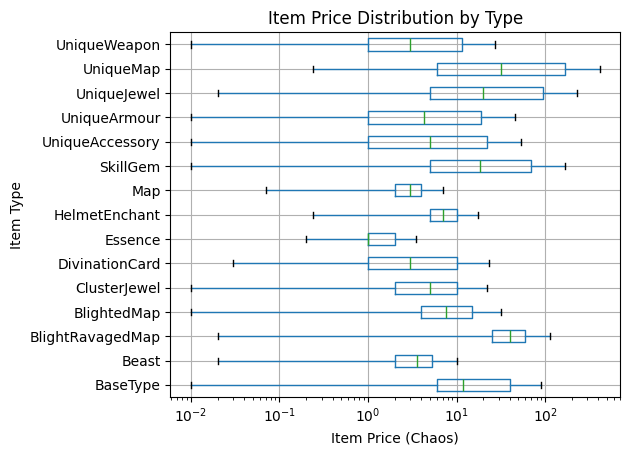

In [78]:
top_types = items_processed["Type"].value_counts().head(15).index
price_distr_by_type = items_processed[items_processed["Type"].isin(top_types)]

plt.figure(figsize=(12,8))

price_distr_by_type.boxplot(column="Value", by="Type", vert=False, showfliers=False)

plt.xscale("log")
plt.xlabel("Item Price (Chaos)")
plt.ylabel("Item Type")
plt.title("Item Price Distribution by Type")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Conclusion:** The boxplot reveals substantial variability in item prices across most item categories.In many cases, item prices vary by several orders of magnitude indicating that items within the same category can differ greatly in value. This suggests that the market price of an item is strongly influenced by its specific properties and rarity rather than by its general type alone. At the same time, some categories exhibit relatively narrower price ranges, indicating more stable market valuations. In contrast, other categories display very wide distributions, where a small number of extremely valuable items coexist with a large number of low-value items.

### Price dominance within item types

In [85]:
# Most valuable item in each type
top_item_per_type = (items_processed.loc[items_processed.groupby("Type")["Value"].idxmax()][["Type", "Name", "Value", "Confidence"]].sort_values("Value", ascending=False).reset_index(drop=True))
top_item_per_type

,Type,Name,Value,Confidence
0,BaseType,Stygian Vise,3859155.000,Low
1,UniqueArmour,The Apostate,2723020.000,Low
2,UniqueAccessory,Demigod's Eye,2424828.000,Low
3,UniqueWeapon,Demigod's Authority,2332007.680,Low
4,SkillGem,Volcanic Fissure of Snaking,2195928.600,Low
5,BlightRavagedMap,Blight-ravaged Courthouse Map,1820517.930,Low
6,Beast,Crypt Weaver,1621692.600,Low
7,UniqueMap,Cursed Refuse,1549845.000,Low
8,UniqueJewel,Emperor's Mastery,913847.220,Low
9,ForbiddenJewel,Indomitable Resolve,446858.000,Low


The extremely high price values observed above are associated exclusively with low confidence estimates. These values typically correspond to very rare items, special game artefacts or exceptionally high prices obtained by top players. As a result, they represent statistical outliers rather than typical market behaviour and therefore do not accurately reflect the representative value of the most expensive items within each type. To ensure more reliable results, the analysis was restricted to observations with medium and high confidence levels only.

In [88]:
# Most valuable item in each type with Medium or High confidence
high_conf_items_processed = items_processed[items_processed["Confidence"].isin(["Medium", "High"])]
highconf_top_item_per_type = (high_conf_items_processed.loc[high_conf_items_processed.groupby("Type")["Value"].idxmax()][["Type", "Name", "Value", "Confidence"]].sort_values("Value", ascending=False).reset_index(drop=True))
highconf_top_item_per_type

,Type,Name,Value,Confidence
0,UniqueAccessory,Replica Bated Breath,1636590.860,Medium
1,UniqueJewel,Voices,870858.000,High
2,SkillGem,Awakened Enlighten Support,734526.820,Medium
3,ForbiddenJewel,Undeniable,314961.600,High
4,UniqueRelic,The Original Scripture,234107.230,High
5,BaseType,Simplex Amulet,170237.720,Medium
6,UniqueFlask,Progenesis,107685.915,Medium
7,Runegraft,Runegraft of the Angler,102706.690,High
8,UniqueArmour,Asphyxia's Wrath,97133.820,Medium
9,UniqueWeapon,Foulborn Hand of Thought and Motion,88400.000,High


In [ ]:
#Price dominance of top Items within Types
median_price = high_conf_items_processed.groupby("Type")["Value"].median() 
highconf_top_item_per_type["median_type_value"] = highconf_top_item_per_type["Type"].map(median_price) 
highconf_top_item_per_type["value_vs_median"] = (highconf_top_item_per_type["Value"] / highconf_top_item_per_type["median_type_value"]).round(2) 
highconf_top_item_per_type

,Type,Name,Value,Confidence,median_type_price,median_type_value,value_vs_median
0,UniqueAccessory,Replica Bated Breath,1636590.860,Medium,5.00,5.00,327318.17
1,UniqueJewel,Voices,870858.000,High,20.00,20.00,43542.90
2,SkillGem,Awakened Enlighten Support,734526.820,Medium,12.00,12.00,61210.57
3,ForbiddenJewel,Undeniable,314961.600,High,100.00,100.00,3149.62
4,UniqueRelic,The Original Scripture,234107.230,High,10.00,10.00,23410.72
5,BaseType,Simplex Amulet,170237.720,Medium,9.30,9.30,18305.13
6,UniqueFlask,Progenesis,107685.915,Medium,5.00,5.00,21537.18
7,Runegraft,Runegraft of the Angler,102706.690,High,10.00,10.00,10270.67
8,UniqueArmour,Asphyxia's Wrath,97133.820,Medium,4.00,4.00,24283.46
9,UniqueWeapon,Foulborn Hand of Thought and Motion,88400.000,High,2.00,2.00,44200.00


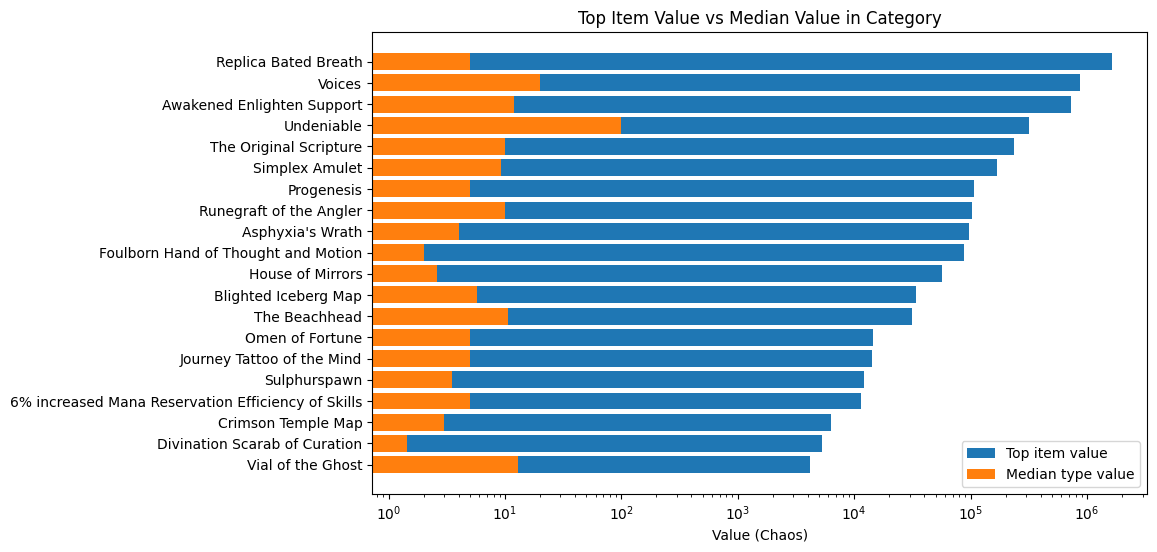

In [94]:
top20 = highconf_top_item_per_type.head(20)

plt.figure(figsize=(10,6))

y = range(len(top20))

plt.barh(y, top20["Value"], label="Top item value")
plt.barh(y, top20["median_type_value"], label="Median type value")
plt.yticks(y, top20["Name"])
plt.xlabel("Value (Chaos)")
plt.xscale("log")
plt.title("Top Item Value vs Median Value in Category")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

### Market Value Concentration

In [96]:
# Average value of each item across all observations
item_values = (high_conf_items_processed.groupby("Name")["Value"].mean().sort_values(ascending=False))

# Total market value (sum of average item values)
total_market_value = item_values.sum()

# Value of the 20 most expensive items
top20_items = item_values.head(20)
top20_value = top20_items.sum()

# Percentage of total market value represented by top 20 items
percentage_top20 = (top20_value / total_market_value) * 100
print(f"Top 20 items generate {percentage_top20:.2f}% of total market value")



Top 20 items generate 44.50% of total market value


**Conclusion:** The boxplot analysis revealed that price distributions within many item categories are highly skewed, with most items having relatively low prices while a small number of items reach extremely high values. This pattern reflects a characteristic feature of the Path of Exile economy, where the market structure is highly uneven and dominated by a long tail of rare, high-value items.

This observation is further supported by comparing the most expensive item in each type with the median value of that type. In many cases, the top item is several orders of magnitude more valuable than the typical item within the same type, confirming that the economic value of item types is largely driven by a small number of extremely rare items.

The analysis of market value concentration provides additional evidence for this pattern. The twenty most expensive items account for approximately 44.5% of the total market value, indicating that a relatively small number of items dominate a substantial portion of the overall economy.

Due to the substantial variability of prices within many categories, analysing all items simultaneously may obscure meaningful patterns. Therefore, the future planned analysis will focus on a selected subset of representative items, which allows for a clearer investigation of price dynamics and market behaviour across different leagues.
